<a href="https://colab.research.google.com/github/Samuelisusername/Large-Language-Models/blob/main/Tutorial_3_Implementing_an_Elman_RNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
try:
  import dill
except:
  !git clone https://github.com/valebi/rnn-tutorial-utils.git
  !mv rnn-tutorial-utils/* .
  %pip install -r requirements_colab.txt

Cloning into 'rnn-tutorial-utils'...
remote: Enumerating objects: 13, done.
remote: Counting objects: 100% (13/13), done.
remote: Compressing objects: 100% (11/11), done.
remote: Total 13 (delta 0), reused 13 (delta 0), pack-reused 0
Receiving objects: 100% (13/13), 94.36 KiB | 1.85 MiB/s, done.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 1.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 4.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 42.2 MB/s eta 0:00:00
  Attempting uninstall: scikit-learn
    Found existing installation: scikit-learn 1.2.2
    Uninstalling scikit-learn-1.2.2:
      Successfully uninstalled scikit-learn-1.2.2
  Attempting uninstall: seaborn
    Found existing installation: seaborn 0.13.1
    Uninstalling seaborn-0.13.1:
      Successfully uninstalled seaborn-0.13.1


In [ ]:
import itertools
import dill
import numpy as np
import scipy

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import torch
from torch import nn
from torch.nn import functional as F

from tqdm.notebook import trange

from matplotlib import pyplot as plt
import seaborn as sns

from dataset import RegularDataset
from symbols import EOS, PAD
from IPython.display import display, HTML
from copy import deepcopy
from tqdm import tqdm
from typing import Tuple

np.random.seed(12)
torch.manual_seed(12)

# Let's build our own Elman RNN LM in pytorch!
We're about to train our first recursive language model - an Elman RNN - on two different tasks:
1. The Brown NLTK corpus (to show how it works on real data)
2. A simple regular language (to empirically verify its expressiveness)

## The Brown NLTK corpus
### The task

We want to train a language model on a set of sentences by modeling
$$ p(y) = p(EOS | y)\prod_{t=1}^{|y|}p(y_t | y_{<t}) $$

with an Elman RNN LM.
The train datasets yield tuples (x, y) of encoded inputs and targets: Given our objective, i.e. learning

$$ p(y_t | y_{<t}) = \text{softmax}(Eh_{t-1}) $$

we simply choose the targets to be the inputs shifted by one time step.
Note that we only need to pass the sentence through the model once at training stage: no information is leaked to the future, so we can apply the cross-entropy loss at every time step.
In order to allow batched training, the inputs are padded to the length of the longest sequence in the dataset.


Now let's take a look at the samples

In [ ]:
from dataset import BrownDataset

brown_train_dataset = BrownDataset(split="train", n_train = 20000, n_test = 500)
brown_test_dataset = BrownDataset(split="test", n_train = 20000, n_test = 500)

sample_x, sample_y = brown_train_dataset[0]
print(f"decoded sample input: {brown_train_dataset.decode(sample_x)}")
print(f"decoded sample output (shifted by 1): {brown_train_dataset.decode(sample_y)}")
print(f"encoded sample input: {sample_x[:100]} of shape {sample_x.shape}")
print(f"encoded sample output: {sample_y[:100]} of shape {sample_y.shape}")
print(f"sample tokens: {brown_train_dataset.tokens[:10]}")
print(f"number of tokens: {len(brown_train_dataset.tokens)}")
print(f"number of samples: {len(brown_train_dataset)}")

[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Unzipping corpora/brown.zip.
[nltk_data] Downloading package brown to /root/nltk_data...
[nltk_data]   Package brown is already up-to-date!


decoded sample input: the fulton county grand jury said friday an investigation of atlanta's recent primary election produced `` no evidence '' that any irregularities took place . EOS * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
decoded sample output (shifted by 1): fulton county grand jury said friday an investigation of atlanta's recent primary election produced `` no evidence '' that any irregularities took place . EOS * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * * *
encoded sample input: tensor([10990, 10809, 14028, 25603, 22407, 14782, 

### Model definition

First, let's define the model. It implements the dynamics defined by

$$ h_{t+1} = ReLU(Uh_t + Vx_t + b) $$

where $h_t$ is the hidden state at time $t$, $x_t$ is the input at time $t$ (one-hot encoded), and $U, V, b$ are the weights and biases of the network.

In [ ]:
@torch.jit.script
def elman_recursive_dynamics(h0: torch.Tensor, x: torch.Tensor, U : torch.Tensor, V : torch.Tensor, b : torch.Tensor) -> torch.Tensor:
    batch_size = x.size(0)
    hidden_dim = U.size(0)

    hs = []
    h = h0
    for t in range(x.size(1)):
        x_t = x[:, t, :]
        h = torch.relu(
            U @ h.t()
            + V @ x_t.t()
            + b * torch.ones((hidden_dim, batch_size), device=h.device)
        ).t()
        hs.append(h)

    h = torch.stack(hs, dim=1)
    return h

class ElmanLM(nn.Module):
    def __init__(
        self,
        input_size: int,
        output_size: int,
        hidden_dim: int,
        device: str = "cpu",
    ):
        super(ElmanLM, self).__init__()

        self.device = device
        self.hidden_dim = hidden_dim
        self.input_size = input_size

        self.U = nn.Parameter(
            torch.zeros(
                (hidden_dim, hidden_dim), device=self.device, requires_grad=True
            )
        )
        self.V = nn.Parameter(
            torch.zeros(
                (hidden_dim, input_size), device=self.device, requires_grad=True
            )
        )
        self.b = nn.Parameter(
            torch.zeros((hidden_dim, 1), device=self.device, requires_grad=True)
        )

        self.E = nn.Parameter(
            torch.zeros(
                (output_size, hidden_dim), device=self.device, requires_grad=True
            )
        )
        self.h0 = nn.Parameter(
            torch.zeros(
                (1, hidden_dim), device=self.device, requires_grad=False
            ),
            requires_grad=False
        )
        nn.init.xavier_uniform_(self.U)
        nn.init.xavier_uniform_(self.V)
        nn.init.xavier_uniform_(self.b)
        nn.init.xavier_uniform_(self.E)


    def forward(self, x: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        x = self.encode_one_hot(x)
        h = elman_recursive_dynamics(self.h0, x, self.U, self.V, self.b)

        y = h @ self.E.T

        return h, y

    def encode_one_hot(self, x: torch.Tensor) -> torch.Tensor:
        # this is a bit ugly because one_hot doesn't like the -1 padding
        x_non_negative = x.clone()
        x_non_negative[x < 0] = 0
        x_one_hot = torch.nn.functional.one_hot(x_non_negative, num_classes=self.input_size)
        x_one_hot[x == -1] = 0
        return x_one_hot.float()

### Basic training loop

In [ ]:
def create_model(alphabet_size, D, device):
    rnn = ElmanLM(
        input_size=alphabet_size,
        output_size=alphabet_size,
        hidden_dim=D,
        device=device
    )
    rnn = torch.jit.script(rnn)
    loss_criterion = nn.CrossEntropyLoss(ignore_index=-1)
    optimizer = torch.optim.Adam(rnn.parameters(), weight_decay=1e-5)
    return rnn, loss_criterion, optimizer

In [ ]:
def train_rnn(rnn, loss_criterion, optimizer, n_epochs, batch_size, train_dataset, test_dataset, device):
    validation_cross_entropies = []
    C = rnn.input_size

    x_test, y_test = test_dataset[:]
    train_dataloader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    test_dataloader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    rnn.train()
    rnn = rnn.to(device)
    for epoch in trange(n_epochs):
        epoch_loss = 0
        for x, y in train_dataloader:
            optimizer.zero_grad()

            x = x.to(device)
            y = y.to(device)

            _, logits = rnn(x)

            loss = loss_criterion(logits.reshape(-1, C), y.reshape(-1))
            epoch_loss += loss.item()

            loss.backward()
            optimizer.step()


        val_cross_entropy = 0
        val_ppl = 0
        for x_test, y_test in test_dataloader:
            with torch.no_grad():
                test_mask = (x_test.reshape(-1) != -1) * (x_test.reshape(-1) != test_dataset.sym2idx[EOS])
                y_oh = F.one_hot(y_test.reshape(-1)[test_mask]).argmax(dim=-1).numpy()
                x_test, y_test = x_test.to(device), y_test.to(device)
                enc, logits = rnn(x_test.to(device))

                val_cross_entropy += loss_criterion(logits.view(-1, C), y_test.reshape(-1).to(device)).item()
                P_logits = logits.reshape(-1, logits.shape[-1])[test_mask].cpu().detach().numpy()
                if len(P_logits.T) < 32: # no more than 32 classes -> calculate PPL in numpy
                    val_ppl += np.exp(-np.mean(np.choose(y_oh, P_logits.T) - scipy.special.logsumexp(P_logits, axis=-1)))
                else:
                    val_ppl += np.nan

        val_cross_entropy /= len(test_dataloader)
        val_ppl /= len(test_dataloader)
        validation_cross_entropies.append(val_cross_entropy)

        if epoch % 1 == 0:
            print(f"Epoch: {epoch}/{n_epochs}")
            print(f"\t Train Loss: {epoch_loss:.3f}")
            print(f"\tCE:   {val_cross_entropy:.3f}")
            if len(P_logits.T) < 32:
                print(f"\tPPL:   {val_ppl:.3f}")
    return validation_cross_entropies

def plot_convergence(validation_cross_entropies):
    sns.set(style="whitegrid")
    sns.lineplot(x=range(len(validation_cross_entropies)), y=validation_cross_entropies, label="Val. Cross-Entropy Loss (Custom Elman Implementation)")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (Cross Entropy)")
    plt.title("Loss Trend Over Epochs")
    plt.show()

### Let's train!

In [ ]:
D = 16 # hidden layer size
C = len(brown_train_dataset.tokens) # number of classes (symbols in the alphabet)
batch_size = 128 # how many samples to process at once
device = "cuda" if torch.cuda.is_available() else "cpu" # whether to use GPU or CPU
n_epochs = 7 # how many times to iterate over the entire dataset

In [ ]:
rnn, loss_criterion, optimizer = create_model(C, D, device)

  0%|          | 0/7 [00:00<?, ?it/s]

Epoch: 0/7
	 Train Loss: 1305.167
	CE:   11.596
Epoch: 1/7
	 Train Loss: 1133.179
	CE:   11.468
Epoch: 2/7
	 Train Loss: 1106.765
	CE:   11.342
Epoch: 3/7
	 Train Loss: 1078.637
	CE:   11.384
Epoch: 4/7
	 Train Loss: 1053.825
	CE:   11.483
Epoch: 5/7
	 Train Loss: 1037.290
	CE:   11.594
Epoch: 6/7
	 Train Loss: 1025.331
	CE:   11.708


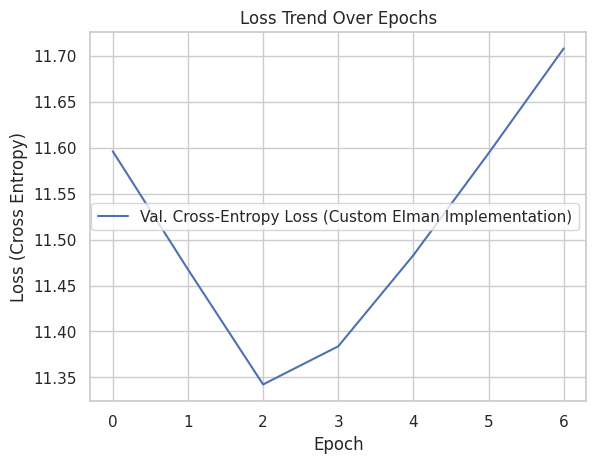

In [ ]:
validation_cross_entropies = train_rnn(rnn, loss_criterion, optimizer, n_epochs, batch_size, brown_train_dataset, brown_test_dataset, device)
plot_convergence(validation_cross_entropies)

### Generating strings

In [ ]:
def predict_next_word(rnn, sentence_start):
    rnn.eval()
    sentence_start = brown_train_dataset.encode(sentence_start).unsqueeze(0).to(device)
    enc, logits = rnn(sentence_start)
    next_word_probs = F.softmax(logits, dim=-1)
    decoded_next_word = brown_train_dataset.decode([next_word_probs[0,-1].argmax().item()])
    return decoded_next_word

eval_sentence_start = "a dog ran"
for i in range(10):
    eval_sentence_start += " " + predict_next_word(rnn, eval_sentence_start)
print(eval_sentence_start)

a dog ran , the the , , the the . EOS EOS


You'll notice that the LM starts overfitting rather quickly. Do you have ideas why that might happen?

Also, some words keep repeating during generation. How does that relate to the problem? And how could we improve the model?

### Visualizing the Vanishing Gradient

The vanishing gradient problem is a well-known issue in training RNNs.
Though the Elman RNN can theoretically model long-range dependencies, in practice, it often fails to do so by backpropagation. This comes from the repeated multiplication of the same Jacobian.

Let's see if we can observe this effect empirically. We'll mask the loss of all tokens except the last one (EOS) and plot the norm of the gradient that reaches h_0 (the initial state) for different scales of the weight matrix U.

In [ ]:
def get_last_label_gradient_norms(rnn, test_dataset):
    rnn.h0.requires_grad = True
    norms = []
    lengths = []
    for x, y in tqdm(test_dataset):
        x = x.to(device).clone()
        y = y.to(device).clone()
        for j in range(len(y)-1):
            if y[j+1] != -1: # mask loss of everything except EOS token
                y[j] = -1
            else: # store the position of the EOS token
                lengths.append(j)
                break
        rnn.zero_grad()
        _, logits = rnn(x.unsqueeze(0))
        loss = loss_criterion(logits.reshape(-1, rnn.input_size), y.reshape(-1))
        loss.backward()
        norms.append(rnn.h0.grad.norm().item())

    assert len(norms) == len(lengths)

    return norms, lengths

def scale_weights(rnn, factor):
    rnn = deepcopy(rnn)
    rnn.U.data = rnn.U.data * factor
    return rnn


norms, lengths = get_last_label_gradient_norms(deepcopy(rnn), brown_test_dataset)
norms_large, lengths_large = get_last_label_gradient_norms(scale_weights(rnn, 2), brown_test_dataset)
norms_small, lengths_small = get_last_label_gradient_norms(scale_weights(rnn, 0.5), brown_test_dataset)

  0%|          | 0/500 [00:00<?, ?it/s]/usr/local/lib/python3.10/dist-packages/torch/nn/modules/module.py:2459: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more informations. (Triggered internally at aten/src/ATen/core/TensorBody.h:489.)
  if p.grad is not None:
100%|██████████| 500/500 [00:20<00:00, 23.83it/s]


Text(0.5, 1.0, 'Strength of Gradient of $h_0$ w.r.t. Loss at EOS token position vs. EOS position')

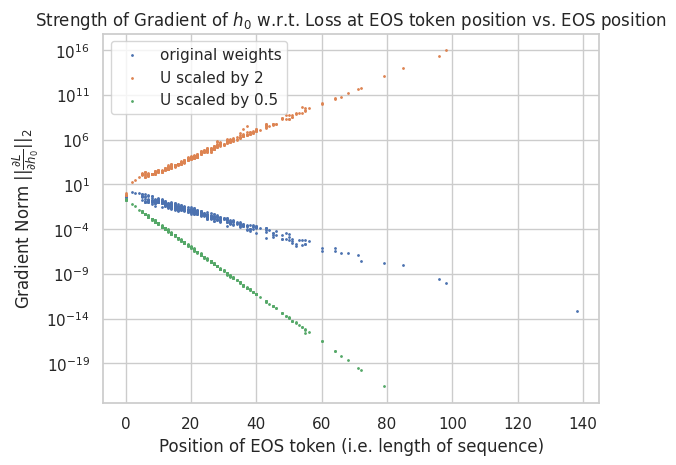

In [ ]:
plt.scatter(lengths, norms, s=1)
plt.scatter(lengths_large, norms_large, s=1)
plt.scatter(lengths_small, norms_small, s=1)
plt.yscale("log")
plt.legend(["original weights", "U scaled by 2", "U scaled by 0.5"])
plt.xlabel("Position of EOS token (i.e. length of sequence)")
plt.ylabel(r"Gradient Norm $||\frac{\partial L}{\partial h_0}||_2$")
plt.title(r"Strength of Gradient of $h_0$ w.r.t. Loss at EOS token position vs. EOS position")

## Learning a regular language

### First, let's take a look at the FSA data

We generated a dataset of strings generated from a simple regular language, and we want to see if the Elman RNN can learn it. The language is defined by the following FSA:

In [ ]:
data_dir = "data/"
display(HTML(open(data_dir + "fsa.html", "r").read()))

In [ ]:
train_dataset = RegularDataset(data_dir, "train")
test_dataset = RegularDataset(data_dir, "test")

In [ ]:
sample_input = train_dataset[0][0].cpu().numpy()[:200]
print("Observe the non-encoded string & compare it to the FSA. Note the EOS symbol as well as the PAD token *")
print(train_dataset.decode(sample_input))
print("Now check the index-encoded inputs (each entry represents the index of a symbol in the alphabet) and the corresponding outputs (each entry represents the index of a symbol in the alphabet)")
print(sample_input)

Observe the non-encoded string & compare it to the FSA. Note the EOS symbol as well as the PAD token *
baabbaaaaaabacacabbbacacacacacabbaabacabbaaababEOS************************************************************************************************************************************************
Now check the index-encoded inputs (each entry represents the index of a symbol in the alphabet) and the corresponding outputs (each entry represents the index of a symbol in the alphabet)
[ 1  0  0  1  1  0  0  0  0  0  0  1  0  2  0  2  0  1  1  1  0  2  0  2
  0  2  0  2  0  2  0  1  1  0  0  1  0  2  0  1  1  0  0  0  1  0  1  4
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1 -1
 -

### Now, let's train another Elman RNN

In [ ]:
D = 64 # hidden layer size
C = len(train_dataset.alphabet) # number of classes (symbols in the alphabet)
batch_size = 128 # how many samples to process at once
device = "cuda" if torch.cuda.is_available() else "cpu" # whether to use GPU or CPU
n_epochs = 20 # how many times to iterate over the entire dataset

In [ ]:
rnn, loss_criterion, optimizer = create_model(C, D, device)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch: 0/20
	 Train Loss: 133.459
	CE:   0.807
	PPL:   2.242
Epoch: 1/20
	 Train Loss: 88.896
	CE:   0.638
	PPL:   1.892
Epoch: 2/20
	 Train Loss: 76.162
	CE:   0.583
	PPL:   1.792
Epoch: 3/20
	 Train Loss: 72.002
	CE:   0.565
	PPL:   1.759
Epoch: 4/20
	 Train Loss: 70.437
	CE:   0.557
	PPL:   1.746
Epoch: 5/20
	 Train Loss: 69.656
	CE:   0.552
	PPL:   1.737
Epoch: 6/20
	 Train Loss: 69.262
	CE:   0.551
	PPL:   1.735
Epoch: 7/20
	 Train Loss: 68.986
	CE:   0.548
	PPL:   1.729
Epoch: 8/20
	 Train Loss: 68.812
	CE:   0.547
	PPL:   1.728
Epoch: 9/20
	 Train Loss: 68.696
	CE:   0.548
	PPL:   1.730
Epoch: 10/20
	 Train Loss: 68.587
	CE:   0.549
	PPL:   1.731
Epoch: 11/20
	 Train Loss: 68.553
	CE:   0.547
	PPL:   1.727
Epoch: 12/20
	 Train Loss: 68.569
	CE:   0.546
	PPL:   1.726
Epoch: 13/20
	 Train Loss: 68.522
	CE:   0.544
	PPL:   1.723
Epoch: 14/20
	 Train Loss: 68.432
	CE:   0.545
	PPL:   1.725
Epoch: 15/20
	 Train Loss: 68.424
	CE:   0.544
	PPL:   1.723
Epoch: 16/20
	 Train Loss: 68.408

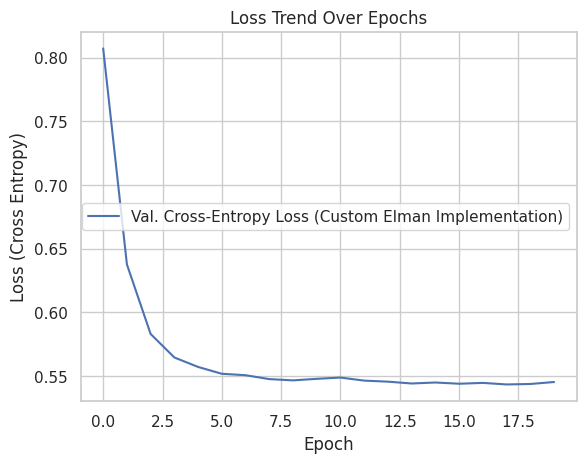

In [ ]:
validation_cross_entropies = train_rnn(rnn, loss_criterion, optimizer, n_epochs, batch_size, train_dataset, test_dataset, device)
plot_convergence(validation_cross_entropies)

### Nice, our Elman RNN can learn regular languages! Now let's see what the hidden states represent

We can directly get the hidden states $h_t$ from the model (for the test set)

In [ ]:
x_test, y_test = test_dataset[:]
rnn.eval()
enc_padded, _ = rnn(x_test.to(device))
enc = enc_padded.reshape(-1, enc_padded.shape[-1])[x_test.reshape(-1) != -1].cpu().detach().numpy()
print("shape of encodings of all test states:")
print(f"by sample (padded): {enc_padded.shape}")
print(f"flattened {enc.shape}")

shape of encodings of all test states:
by sample (padded): torch.Size([4000, 148, 64])
flattened (82824, 64)


Now, if our model truly learned the regular language: Can we recognize the FSA states in the hidden states?
To find out, we project the hidden states to a 2D space using PCA or t-SNE and visualize the FSA states by color.

### Get the ground truth states of the FSA

In [ ]:
qss = dill.load(open(data_dir + "test_states.dill", "rb"))
labels = list(itertools.chain.from_iterable(qss))
assert len(enc) == len(labels)
len(labels)

82824

### Let's see if we recognize the FSA states in the hidden states!

In [ ]:
# fit projection
projection = "t-SNE" # "PCA" or "t-SNE" for visualization of the hidden states h_t later
projection_model = TSNE(n_components=2) if projection == "t-SNE" else PCA(n_components=2, whiten=True)
Z = projection_model.fit_transform(enc)

Text(0.5, 1.0, 't-SNE projection of RNN Hidden States, colored by FSA state during generation')

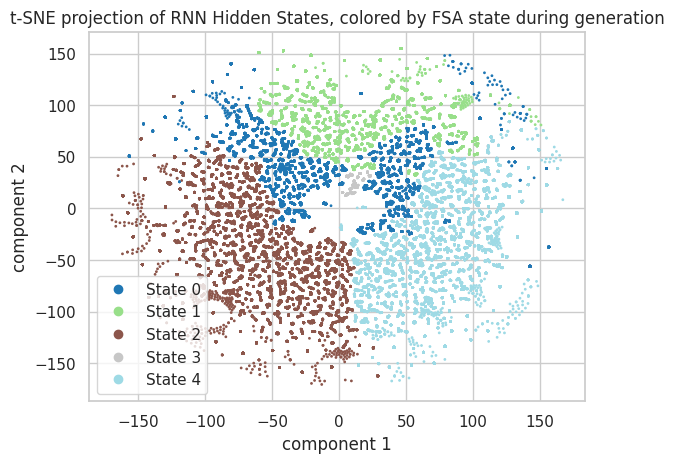

In [ ]:
# visualize
scatter = plt.scatter(Z[:,0], Z[:,1], c=labels, cmap="tab20", s=1)
plt.legend(handles=scatter.legend_elements()[0], labels=[f"State {i}" for i in range(len(set(labels)))])
plt.xlabel("component 1")
plt.ylabel("component 2")
plt.title(f"{projection} projection of RNN Hidden States, colored by FSA state during generation")